## Практическое задание №3

В файле **WIPO-GII_2022.xlsx** содержаться данные по странам о показателях, используемых для расчета Global Innovation Index за 2022 год. 

### В файле следующие переменные:																																
- Country
- Business environment
- Business sophistication index
- Citable documents H-index
- Creative goods and services
- Creative goods exports, % total trade
- Creative outputs index
- Cultural and creative services exports, % total trade
- Domestic market scale, bn PPP
- Ecological sustainability
- Expenditure on education, % GDP
- Firms offering formal training, %
- General infrastructure
- Government effectiveness
- Government's online service
- Graduates in science and engineering, %
- Gross expenditure on R&D, % GDP
- High-tech exports, % total trade
- High-tech imports, % total trade
- High-tech manufacturing, %
- Human capital and research index
- Information and Communications Technology access
- Information and Communications Technology services exports, % total trade
- Information and Communications Technology services imports, % total trade
- Information and Communications Technology use
- Infrastructure index
- Intangible assets
- Joint venture/strategic alliance deals/bn PPP GDP
- Knowledge absorption
- Knowledge and technology outputs index
- Knowledge workers
- Knowledge-intensive employment, %
- Logistics performance
- Market sophistication index
- Mobile app creation/bn PPP GDP
- Online creativity
- PISA scales in reading, maths and science
- Political and operational stability
- Political environment
- Pupil-teacher ratio, secondary
- QS university ranking average score of top 3 universities
- Research and development (R&D)
- Scientific and technical articles/bn PPP GDP
- Software spending, % GDP
- Tertiary education
- Tertiary enrolment, % gross
- University-industry R&D collaboration
- Region
- Region2
- Euro area
- European Union
- OECD members
- Least developed countries
- Income
- High income

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import calinski_harabasz_score, silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.metrics import adjusted_rand_score

df1 = pd.read_excel('WIPO-GII_2022.xlsx')

Выполните, пожалуйста, задания.

**1. Построение признакового пространства и снижение размерности для кластеризации**

- Выберите не менее 10 числовых признаков из датасета, которые потенциально подходят для построения модели кластеризации. Обоснуйте их выбор (информативность, вариативность, отсутствие пропусков, предметный смысл).

- Проведите корреляционный анализ выбранных признаков. Сделайте вывод о наличии или отсутствии мультиколлинеарности.

- При наличии значимых корреляций выполните снижение размерности данных. Используйте метод главных компонент (PCA). Возможно, что имеет смысл выделить компоненты не на основе всех рассматриваемых признаков, а только на части изначально отобранных. Определите оптимальное количество компонент. Для каждой выделенной компоненты укажите процент объяснённой вариации; проанализируйте нагрузки; дайте компоненте осмысленное название и обоснуйте его.

- Сохраните полученные компоненты в датасете в виде новых переменных и используйте их для дальнейшей кластеризации.

- Сформируйте финальный список признаков по которым будет проведена кластеризация. Это могут быть только исходные признаки; только сформированные компоненты или же комбинация из исходных признаков и компонентов. Приведите аргументы в пользу того, что финальный список признаков может быть использован для кластеризации объектов наблюдения.

**!Если не удается выделить компоненты на имеющихся данных, то приведите расчеты и аргументы, подтверждающие это.**

In [2]:
numeric_features = df1.select_dtypes(include='number').filter(regex='_2022$').columns.tolist()
display(pd.Series(numeric_features, name='Количественные показатели').to_frame())

,Количественные показатели
0,Business environment_2022
1,Business sophistication index_2022
2,Citable documents H-index_2022
3,Creative goods and services_2022
4,"Creative goods exports, % total trade_2022"
5,Creative outputs index_2022
6,"Cultural and creative services exports, % tota..."
7,"Domestic market scale, bn PPP$_2022"
8,Ecological sustainability_2022
9,"Expenditure on education, % GDP_2022"


**Выбор 10 числовых признаков**

Для кластеризации выбраны показатели, характеризующие условия для инноваций, подготовку кадров, научную деятельность и использование технологий. Для анализа я рассматриваю только показатели за 2022 год.

| Признак | Что показывает |
| --- | --- |
| Government effectiveness | Характеризует эффективность государственного управления и институциональные условия для развития науки и бизнеса. |
| General infrastructure | Отражает инфраструктурные условия, необходимые для деятельности предприятий и внедрения технологий. |
| Information and Communications Technology access | Показывает доступность инфраструктуры, важной для распространения знаний и технологий. |
| Expenditure on education, % GDP | Характеризует финансирование образования. |
| Graduates in science and engineering, % | Отражает долю выпускников по научным и инженерным направлениям. |
| Gross expenditure on R&D, % GDP | Характеризует вложения в исследования и разработки. |
| Scientific and technical articles/bn PPP$ GDP | Отражает результативность научной деятельности с учётом масштаба экономики. |
| Knowledge-intensive employment, % | характеризует долю занятых в профессиях, требующих высокой квалификации и знаний. |
| High-tech manufacturing, % | Показывает роль высокотехнологичного производства в экономике. |
| High-tech exports, % total trade | Характеризует участие страны в международной торговле высокотехнологичными продуктами. |


На следующем шаге проверим корреляции между выбранными признаками, чтобы выяснить, насколько они дублируют информацию друг друга и нужно ли снижать размерность данных.

In [3]:
features = [
    'Government effectiveness_2022',
    'General infrastructure_2022',
    'Information and Communications Technology access_2022',
    'Expenditure on education, % GDP_2022',
    'Graduates in science and engineering, %_2022',
    'Gross expenditure on R&D, % GDP_2022',
    'Scientific and technical articles/bn PPP$ GDP_2022',
    'Knowledge-intensive employment, %_2022',
    'High-tech manufacturing, %_2022',
    'High-tech exports, % total trade_2022',
]

X = df1[features].dropna()


feature_stats = pd.DataFrame({
    'count': X.count(),
    'nunique': X.nunique(),
    'min': X.min(),
    'max': X.max(),
    'std': X.std()
})
feature_stats['missing_before'] = df1[features].isna().sum()
display(feature_stats.round(2))
print(f'Рабочая выборка: {X.shape[0]} стран, {X.shape[1]} признаков.')
print(f'Исключено стран с пропусками: {len(df1) - len(X)} из {len(df1)}.')

,count,nunique,min,max,std,missing_before
Government effectiveness_2022,132,124,0.0,100.0,19.79,7
General infrastructure_2022,132,113,2.9,76.2,15.48,7
Information and Communications Technology access_2022,132,109,0.0,99.6,17.47,7
"Expenditure on education, % GDP_2022",132,114,0.0,100.0,18.98,7
"Graduates in science and engineering, %_2022",132,98,0.0,100.0,28.09,7
"Gross expenditure on R&D, % GDP_2022",132,99,0.0,100.0,19.49,7
Scientific and technical articles/bn PPP$ GDP_2022,132,121,0.0,100.0,23.70,7
"Knowledge-intensive employment, %_2022",132,117,0.0,100.0,25.83,7
"High-tech manufacturing, %_2022",132,102,0.0,100.0,25.19,7
"High-tech exports, % total trade_2022",132,115,0.0,100.0,25.98,7


Рабочая выборка: 132 стран, 10 признаков.
Исключено стран с пропусками: 7 из 139.


**Вывод по отбору признаков.**<br>
В исходном файле 139 стран. Для 7 стран отсутствуют все 46 количественных показателей за 2022 год, поэтому эти строки исключены. В результате для каждого из 10 выбранных признаков имеется 132 страны без пропусков, чего достаточно для анализа.

Выбранные признаки различаются между странами, то есть число уникальных значений составляет от 98 до 124, стандартное отклонение от 15,48 до 28,09. Таким образом, среди них нет постоянных показателей, которые не позволяют различать страны.
Выбранные признаки охватывают несколько содержательных сторон технического развития.

**Корреляционный анализ**<br>

Для начала рассчитаем коэффициенты корреляции Пирсона и построим тепловую карту. Для удобства на графиках и в таблицах используем сокращённые русские названия.

Условно будем считать сильными связи с $|r|>= 0,7$. Статистическую значимость корреляций проверим с помощью Пирсона, сравним исходные p-значения с 0,05. 
Если p-значение меньше 0,05, будем считать линейную связь статистически значимой. 

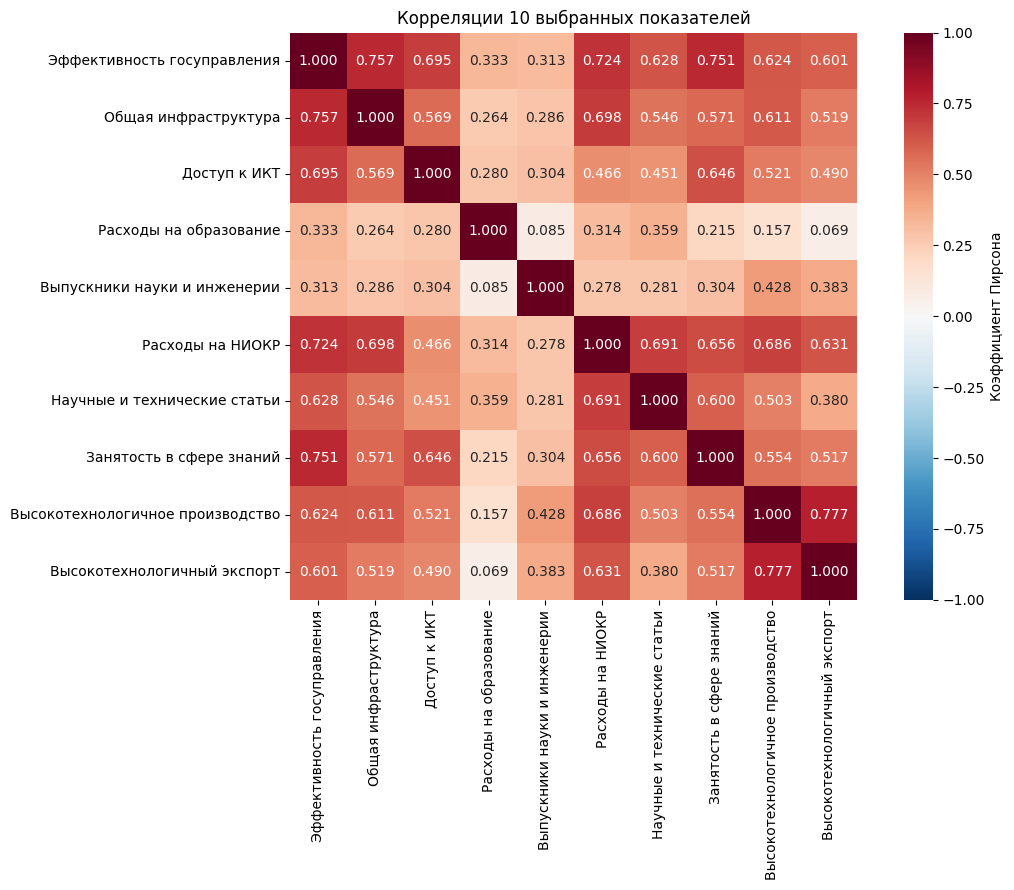

,Признак 1,Признак 2,r,p_value,Значима (p < 0.05)
0,Высокотехнологичное производство,Высокотехнологичный экспорт,0.776834,6.910342e-28,True
1,Эффективность госуправления,Общая инфраструктура,0.757320,8.035093e-26,True
2,Эффективность госуправления,Занятость в сфере знаний,0.750890,3.493769e-25,True
3,Эффективность госуправления,Расходы на НИОКР,0.724153,1.005068e-22,True


Сильных связей: 4 из 45 пар.


In [4]:
from scipy.stats import pearsonr

feature_names = dict(zip(features, [
    'Эффективность госуправления',
    'Общая инфраструктура',
    'Доступ к ИКТ',
    'Расходы на образование',
    'Выпускники науки и инженерии',
    'Расходы на НИОКР',
    'Научные и технические статьи',
    'Занятость в сфере знаний',
    'Высокотехнологичное производство',
    'Высокотехнологичный экспорт',
]))

corr_matrix = X.corr(method='pearson')
#display(corr_matrix.rename(index=feature_names, columns=feature_names).round(3))

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix.rename(index=feature_names, columns=feature_names),
    annot=True, fmt='.3f', cmap='RdBu_r', vmin=-1, vmax=1,
    square=True, cbar_kws={'label': 'Коэффициент Пирсона'},
)

plt.title('Корреляции 10 выбранных показателей')
plt.tight_layout()
plt.show()

pairs = []
for i, first in enumerate(features):
    for second in features[i + 1:]:
        r, p_value = pearsonr(X[first], X[second])
        pairs.append({
            'Признак 1': feature_names[first],
            'Признак 2': feature_names[second],
            'r': r,
            'p_value': p_value,
        })

correlation_pairs = pd.DataFrame(pairs)
correlation_pairs['Значима (p < 0.05)'] = correlation_pairs['p_value'] < 0.05

strong_pairs = correlation_pairs.loc[
    correlation_pairs['r'].abs() >= 0.7
].sort_values('r', ascending=False)

display(strong_pairs.reset_index(drop=True))
print(f'Сильных связей: {len(strong_pairs)} из {len(correlation_pairs)} пар.')

**Вывод по корреляциям.**<br>
Найдены 4 сильные положительные связи:

- высокотехнологичное производство и высокотехнологичный экспорт: r = 0,78;
- эффективность госуправления и общая инфраструктура: r = 0,76;
- эффективность госуправления и занятость в сфере знаний: r = 0,75;
- эффективность госуправления и расходы на НИОКР: r = 0,72.

Все четыре сильные связи статистически значимы, так как исходные p-значения теста Пирсона меньше 0,05.Сильные корреляции указывают на наличие мультиколлинеарности, то есть часть выбранных признаков передаёт похожую информацию. Поэтому применим PCA ко всем 10 признакам. Так мы сможем сократить размерность данных, не исключая отдельные показатели вручную.

**Стандартизация и выбор числа главных компонент**

Перед PCA проведём z-стандартизацию: вычтем среднее и разделим на стандартное отклонение. Хотя все показатели находятся в пределах 0–100, их разброс различается, поэтому без стандартизации признаки с большей дисперсией получили бы больший вес.

,Собственное значение,"Объяснённая вариация, %","Накопленная вариация, %"
0,5.535,55.345,55.345
1,1.121,11.209,66.554
2,0.801,8.011,74.565
3,0.662,6.616,81.180
4,0.579,5.794,86.974
5,0.433,4.333,91.307
6,0.311,3.112,94.419
7,0.218,2.176,96.595
8,0.187,1.866,98.461
9,0.154,1.539,100.000


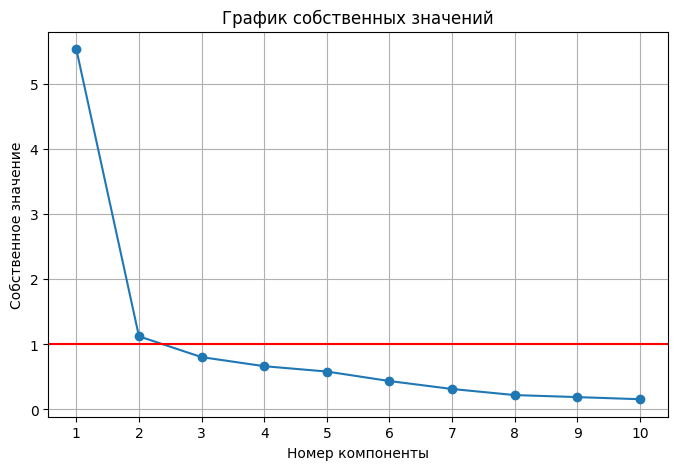

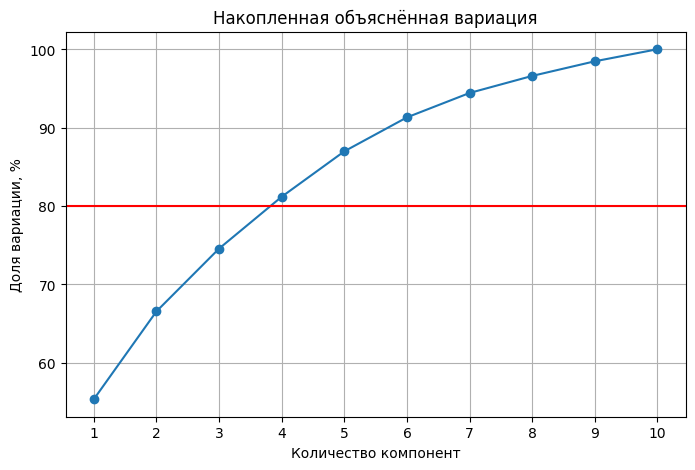

Компонент по критерию Кайзера: 2
Они объясняют, %: 66.55
Компонент для сохранения 80%: 4


In [5]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    index=X.index,
    columns=features
)

pca_full = PCA()
pca_full.fit(X_scaled)

eigenvalues = pca_full.explained_variance_ * (len(X) - 1) / len(X)
variance_share = pca_full.explained_variance_ratio_
cumulative_share = variance_share.cumsum()

pca_diagnostics = pd.DataFrame({
    'Собственное значение': eigenvalues,
    'Объяснённая вариация, %': variance_share * 100,
    'Накопленная вариация, %': cumulative_share * 100
})
display(pca_diagnostics.round(3))

component_numbers = range(1, len(eigenvalues) + 1)

plt.figure(figsize=(8, 5))
plt.plot(component_numbers, eigenvalues, 'o-')
plt.axhline(1, color='red')
plt.title('График собственных значений')
plt.xlabel('Номер компоненты')
plt.ylabel('Собственное значение')
plt.xticks(component_numbers)
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(component_numbers, cumulative_share * 100, 'o-')
plt.axhline(80, color='red')
plt.title('Накопленная объяснённая вариация')
plt.xlabel('Количество компонент')
plt.ylabel('Доля вариации, %')
plt.xticks(component_numbers)
plt.grid()
plt.show()

n_components = (eigenvalues > 1).sum()

n_components_80 = (cumulative_share < 0.8).sum() + 1

print('Компонент по критерию Кайзера:', n_components)
print('Они объясняют, %:', round(variance_share[:n_components].sum() * 100, 2))
print('Компонент для сохранения 80%:', n_components_80)

**Выбор числа компонент.**<br>
Собственные значения первых двух компонент равны 5,535 и 1,121, у третьей = 0,801, чем дальше, тем меньше. Для сохранения не менее 80% вариации понадобились бы четыре компоненты, которые вместе объясняют 81,18%. Мы оставляем две компоненты по критерию Кайзера (который, как я понял, прямо на семинаре не вводили, но обсуждали), чтобы получить более компактное и понятное описание стран. При этом учитываем, что 33,45% вариации теряется. На графике особенно заметна важность первой компоненты.

Первая компонента объясняет 55,35%, вторая 11,21%, то есть в сумме 66,55% вариации. Выбираем это решение как компактное представление общей структуры данных, размерность сокращается с 10 до 2, обе компоненты объясняют больше вариации, чем один стандартизированный исходный признак.

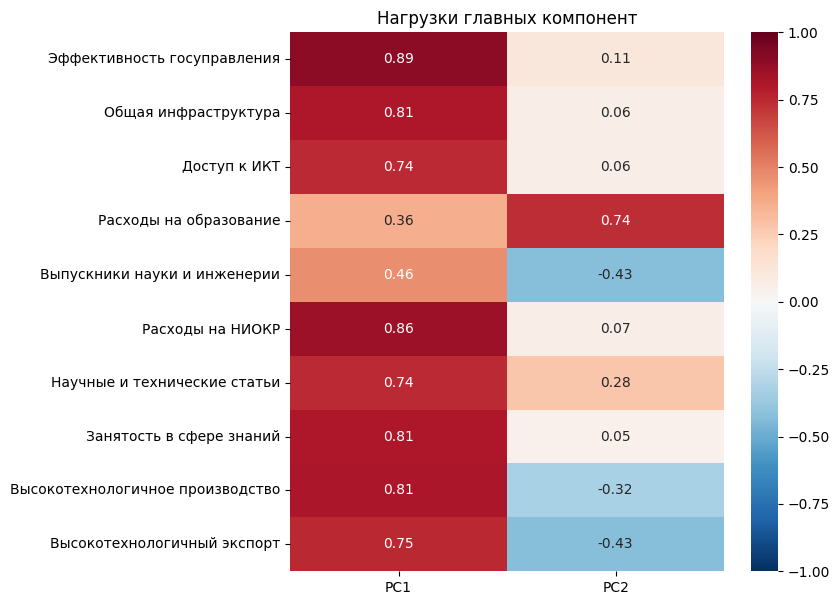

In [6]:
pca = PCA(n_components=2)
component_columns = ['PC1', 'PC2']

components = pd.DataFrame(
    pca.fit_transform(X_scaled),
    index=X.index,
    columns=component_columns
)

loadings = pd.DataFrame({
    'PC1': X_scaled.corrwith(components['PC1']),
    'PC2': X_scaled.corrwith(components['PC2'])
})

loadings.index = [feature_names[name] for name in features]

plt.figure(figsize=(7, 7))
sns.heatmap(loadings, annot=True, fmt='.2f',
            cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('Нагрузки главных компонент')
plt.show()

**Интерпретация компонент**<br>

PC1 - "Общее инновационно-технологическое развитие" (55,35% вариации). Все нагрузки положительные. Наибольшие нагрузки имеют эффективность госуправления = 0,89, расходы на НИОКР = 0,86, высокотехнологичное производство = 0,81, общая инфраструктура = 0,81 и занятость в сфере знаний = 0,81. Таким образом, высокие значения PC1 соответствуют сочетанию развитых институтов и инфраструктуры, исследовательской деятельности и технологичного сектора. 

PC2 - "Образовательные расходы и технологическая специализация" (11,21% вариации). Самая большая положительная нагрузка приходится на расходы на образование = 0,74, поменьше - на научные статьи = 0,28. Отрицательные нагрузки имеют высокотехнологичный экспорт = −0,43, доля выпускников науки и инженерии −0,43 и высокотехнологичное производство −0,32. 
У стран с высоким значением PC2 обычно выше показатель расходов на образование. Низкие значения PC2 чаще связаны с большей долей технических выпускников, высокотехнологичного производства и экспорта.

То есть PC1 описывает общий уровень инновационно-технологического развития, а PC2 показывает дополнительные различия в профиле стран.

**Сохранение компонент и итоговое признаковое пространство**<br>

Добавим PC1 и PC2 в df1 по исходным индексам строк.

In [7]:
df1[['PC1', 'PC2']] = components

cluster_features = ['PC1', 'PC2']
X_cluster = df1.loc[X.index, cluster_features].copy()

display(df1.loc[X.index, ['Country', 'PC1', 'PC2']].head(10))

print('Размер таблицы для кластеризации:', X_cluster.shape)
print('Количество пропусков:', X_cluster.isna().sum().sum())
display(X_cluster.corr().round(3))

,Country,PC1,PC2
0,Cote d'Ivoire,-2.542263,0.130051
1,Czechia,3.448805,-1.157530
2,"Egypt, Arab Rep.",-1.093940,-0.239842
3,"Hong Kong SAR, China",0.669485,0.978505
4,"Iran, Islamic Rep.",0.605435,-0.785389
5,"Korea, Rep.",4.845082,-1.093156
6,Lao PDR,-2.144421,-1.509100
7,Myanmar,-3.313878,-2.286630
9,Russian Federation,0.710656,-0.426737
10,Slovak Republic,1.820576,-1.128869


Размер таблицы для кластеризации: (132, 2)
Количество пропусков: 0


,PC1,PC2
PC1,1.0,-0.0
PC2,-0.0,1.0


**Итог по 1 пункту**<br>
Вместо 10 исходных показателей оставляем две главные компоненты PC1 и PC2. Для всех 132 стран рабочей выборки их значения рассчитаны без пропусков. Корреляция между компонентами близка к нулю, что соответствует свойству PCA. Вместе они объясняют 66,55% вариации исходных стандартизированных данных. Таким образом, мы сократили количество признаков с 10 до 2, потеряв 33,45% вариации.

Для кластеризации в задании 2 используем таблицу X_cluster, в которой находятся только PC1 и PC2.

**2. Кластерный анализ и интерпретация результатов**

- Выберите подходящий алгоритм кластеризации. Кратко обоснуйте выбор (тип данных, размер выборки, интерпретируемость, устойчивость к выбросам). Укажите, почему другие рассмотренные в рамках курса методы не были выбраны.

- Определите оптимальное количество кластеров. Представьте график(и). Обоснуйте принятое решение.

- Рассчитайте описательные статистики по каждому кластеру. Подробно опишите каждый кластер, выделите его ключевые характеристики, отличающие от других кластеров.

- Дайте каждому кластеру осмысленное название. Обоснуйте выбор названий. Сформулируйте итоговые выводы о полученной сегментации.

**Выбор метода и дендрограмма**<br>

Для кластеризации используем таблицу X_cluster. При таком небольшом количестве наблюдений удобно использовать иерархическую кластеризацию и рассмотреть объединение групп на дендрограмме.

K-means также подходит для этих данных, но для каждого разбиения требует заранее задать количество кластеров. Я выбрал метод Варда, чтобы сначала рассмотреть структуру объединения стран на дендрограмме. DBSCAN требует подбора радиуса окрестности и минимального числа соседей, но для первоначального анализа опять же удобнее использовать дерево объединений.

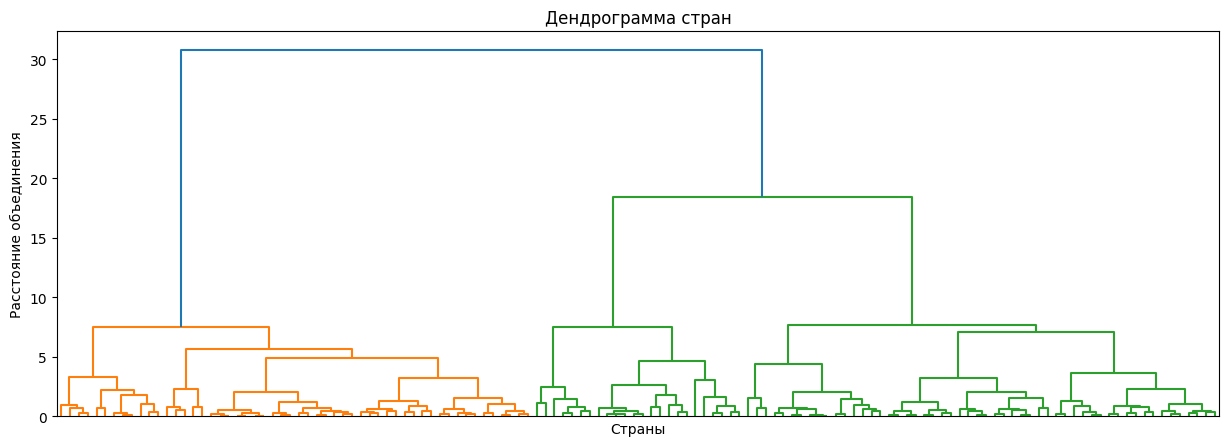

In [8]:
Z = linkage(X_cluster, method='ward')

plt.figure(figsize=(15, 5))
dendrogram(Z, no_labels=True)
plt.title('Дендрограмма стран')
plt.xlabel('Страны')
plt.ylabel('Расстояние объединения')
plt.show()

На дендрограмме последние объединения происходят на высотах примерно 7, 18 и 31. Между ними заметны большие промежутки. Если провести горизонтальную линию между ~ 7 и 18, получим три кластера, а между ~ 18 и 30 - два.

**Выбор количества кластеров**<br>

Сравним варианты от 2 до 10 кластеров. Рассчитаем индекс Калински-Харабаша и средний коэффициент силуэта. Чем выше индекс Калински-Харабаша, тем лучше соотношение различий между группами и разброса внутри них. Силуэт показывает, насколько страны ближе к своей группе, чем к соседней.

In [9]:
ks = range(2, 11)
ch_scores = []
silhouette_scores = []

for k in ks:
    labels = fcluster(Z, t=k, criterion='maxclust')
    ch_scores.append(calinski_harabasz_score(X_cluster, labels))
    silhouette_scores.append(silhouette_score(X_cluster, labels))

scores = pd.DataFrame({
    'Число кластеров': ks,
    'Калински-Харабаш': ch_scores,
    'Силуэт': silhouette_scores
})
display(scores.round(3))

,Число кластеров,Калински-Харабаш,Силуэт
0,2,152.521,0.442
1,3,177.629,0.433
2,4,140.489,0.333
3,5,126.295,0.283
4,6,123.997,0.297
5,7,127.956,0.300
6,8,127.504,0.309
7,9,126.712,0.314
8,10,127.977,0.318


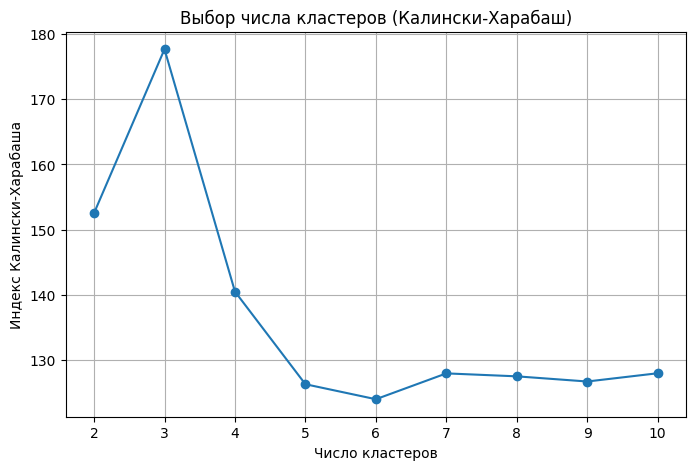

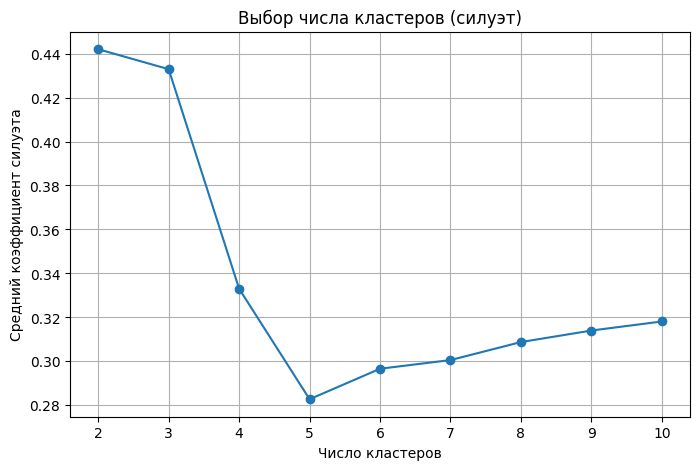

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(ks, ch_scores, 'o-')
plt.title('Выбор числа кластеров (Калински-Харабаш)')
plt.xlabel('Число кластеров')
plt.ylabel('Индекс Калински-Харабаша')
plt.xticks(ks)
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(ks, silhouette_scores, 'o-')
plt.title('Выбор числа кластеров (силуэт)')
plt.xlabel('Число кластеров')
plt.ylabel('Средний коэффициент силуэта')
plt.xticks(ks)
plt.grid()
plt.show()

**Вывод по количеству кластеров.**<br>
Индекс Калински-Харабаша максимален при трёх кластерах (177,63), при двух поменьше - 152,52. Но силуэт немного выше при двух кластерах (0,442),чем при трех (0,433).

Поэтому выбираем три кластера, так как этот вариант поддерживается дендрограммой, имеет наибольший индекс Калински-Харабаша среди того, что мы рассматривали, и даёт более подробное разбиение при небольшой разнице в силуэте. Остальные проверенные варианты (кроме 2 кластеров) уступают разбиению на три группы по обеим метрикам.

**Сохранение кластеров и размеры групп**

Разделим страны на три кластера и добавим номера групп в df1 по исходным индексам. Для семи стран, исключённых из анализа из-за пропусков, номер кластера останется пропущенным.

In [11]:
n_clusters = 3
labels = fcluster(Z, t=n_clusters, criterion='maxclust')

df1['cluster_labels'] = pd.Series(labels, index=X_cluster.index, dtype='Int64')

display(df1.loc[X_cluster.index, ['Country', 'PC1', 'PC2', 'cluster_labels']].head(10))

cluster_sizes = df1['cluster_labels'].value_counts().sort_index()
display(cluster_sizes.to_frame('Количество стран'))

print('Распределено по кластерам:', df1['cluster_labels'].notna().sum())
print('Без кластера из-за пропусков:', df1['cluster_labels'].isna().sum())

,Country,PC1,PC2,cluster_labels
0,Cote d'Ivoire,-2.542263,0.130051,1
1,Czechia,3.448805,-1.157530,2
2,"Egypt, Arab Rep.",-1.093940,-0.239842,1
3,"Hong Kong SAR, China",0.669485,0.978505,3
4,"Iran, Islamic Rep.",0.605435,-0.785389,3
5,"Korea, Rep.",4.845082,-1.093156,2
6,Lao PDR,-2.144421,-1.509100,1
7,Myanmar,-3.313878,-2.286630,1
9,Russian Federation,0.710656,-0.426737,3
10,Slovak Republic,1.820576,-1.128869,3


,Количество стран
cluster_labels,
1,54
2,24
3,54


Распределено по кластерам: 132
Без кластера из-за пропусков: 7


В первый кластер вошли 54 страны, во второй 24, в третий тоже 54. В выбранном разбиении нет групп из одной-двух стран, однако это не означает, что выбросов в данных нет.

**Расположение стран на графике**<br>

Покажем страны на плоскости PC1–PC2 и обозначим кластеры разными цветами. Каждая точка это одна страна. По горизонтали находится первая компонента, по вертикали - вторая.

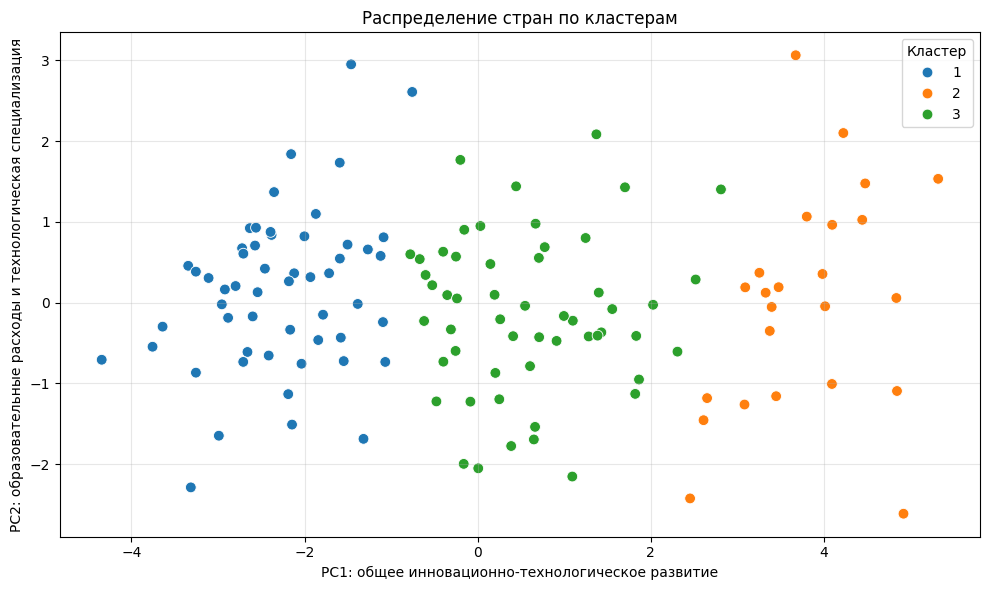

In [12]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df1.loc[X_cluster.index],
    x='PC1', y='PC2', hue='cluster_labels', palette='tab10', s=60
)
plt.title('Распределение стран по кластерам')
plt.xlabel('PC1: общее инновационно-технологическое развитие')
plt.ylabel('PC2: образовательные расходы и технологическая специализация')
plt.legend(title='Кластер')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

На графике первый кластер находится преимущественно слева, второй справа, а третий находится между первых двух. Значит, группы различаются прежде всего по PC1. По PC2 внутри каждой группы виден заметный разброс, поэтому отдельные страны одного кластера могут иметь разные образовательные и технологические профили.

**Сравнение исходных показателей и состава кластеров**<br>

Для ориентира добавим средние по всей рабочей выборке. Затем посмотрим медианы и список стран в каждой группе, медианы помогут проверить, не создаётся ли впечатление о группе только из-за нескольких больших значений. Все значения приводим в дефолтном виде, до z-стандартизации.

In [13]:
cluster_means = df1.groupby('cluster_labels')[features].mean().T
cluster_means['Вся выборка'] = X.mean()
cluster_means = cluster_means.rename(index=feature_names)
display(cluster_means.round(2))

component_means = df1.groupby('cluster_labels')[['PC1', 'PC2']].mean()
display(component_means.round(2))

cluster_labels,1,2,3,Вся выборка
Эффективность госуправления,37.20,82.34,58.03,53.93
Общая инфраструктура,20.91,53.88,34.86,32.61
Доступ к ИКТ,64.01,92.47,88.59,79.24
Расходы на образование,30.87,46.84,37.80,36.61
Выпускники науки и инженерии,22.17,56.12,44.74,37.57
Расходы на НИОКР,2.89,48.80,13.83,15.71
Научные и технические статьи,12.87,56.26,30.01,27.77
Занятость в сфере знаний,17.28,72.01,42.92,37.72
Высокотехнологичное производство,7.43,61.51,34.99,28.54
Высокотехнологичный экспорт,9.39,61.57,36.02,29.77


,PC1,PC2
cluster_labels,,
1,-2.27,0.14
2,3.79,-0.00
3,0.59,-0.14


In [14]:
cluster_medians = df1.groupby('cluster_labels')[features].median().T
cluster_medians = cluster_medians.rename(index=feature_names)
display(cluster_medians.round(2))

cluster_labels,1,2,3
Эффективность госуправления,37.55,80.90,56.85
Общая инфраструктура,21.20,54.55,33.70
Доступ к ИКТ,64.95,92.65,90.00
Расходы на образование,29.65,46.55,36.35
Выпускники науки и инженерии,9.05,56.10,40.10
Расходы на НИОКР,1.90,44.30,11.55
Научные и технические статьи,12.45,58.80,23.80
Занятость в сфере знаний,16.40,73.60,41.50
Высокотехнологичное производство,3.70,60.45,31.50
Высокотехнологичный экспорт,5.40,59.80,32.15


In [15]:
for number in range(1, n_clusters + 1):
    print('Кластер', number)
    print(', '.join(df1.loc[df1['cluster_labels'] == number, 'Country']))
    print()

Кластер 1
Cote d'Ivoire, Egypt, Arab Rep., Lao PDR, Myanmar, Yemen, Rep., Angola, Benin, Botswana, Burkina Faso, Burundi, Cameroon, Ethiopia, Ghana, Guinea, Kenya, Madagascar, Mali, Mauritania, Mozambique, Namibia, Niger, Nigeria, Rwanda, Senegal, Tanzania, Togo, Uganda, Zambia, Zimbabwe, Algeria, Iraq, Albania, Armenia, Azerbaijan, Bosnia and Herzegovina, Bangladesh, Cambodia, Kyrgyz Republic, Mongolia, Nepal, Pakistan, Sri Lanka, Tajikistan, Uzbekistan, Dominican Republic, Ecuador, El Salvador, Guatemala, Honduras, Jamaica, Nicaragua, Paraguay, Peru, Trinidad and Tobago

Кластер 2
Czechia, Korea, Rep., Israel, United Arab Emirates, Austria, Belgium, Denmark, Estonia, Finland, France, Germany, Iceland, Ireland, Netherlands, Norway, Slovenia, Sweden, Switzerland, United Kingdom, Japan, Malaysia, Singapore, Canada, United States

Кластер 3
Hong Kong SAR, China, Iran, Islamic Rep., Russian Federation, Slovak Republic, Turkiye, Mauritius, South Africa, Bahrain, Jordan, Kuwait, Morocco, Om

**Описание кластеров**<br>

Средние по всем десяти исходным показателям выше во втором кластере, далее идет третий и ниже всего в первом. Медианы показывают тот же порядок групп по каждому из десяти признаков. Поэтому я назвал кластеры по инновационно-технологическому уровню.

In [16]:
cluster_names = {
    1: 'Низкий инновационно-технологический уровень',
    2: 'Высокий инновационно-технологический уровень',
    3: 'Средний инновационно-технологический уровень'
}

df1['cluster_name'] = df1['cluster_labels'].map(cluster_names)

cluster_summary = cluster_sizes.to_frame('Количество стран')
cluster_summary['Доля выборки, %'] = cluster_sizes / len(X_cluster) * 100
cluster_summary['Название'] = cluster_summary.index.map(cluster_names)
display(cluster_summary.round(2))

,Количество стран,"Доля выборки, %",Название
cluster_labels,,,
1,54,40.91,Низкий инновационно-технологический уровень
2,24,18.18,Высокий инновационно-технологический уровень
3,54,40.91,Средний инновационно-технологический уровень


**Кластер 1 - "Низкий инновационно-технологический уровень" 54 страны, 40,91% выборки.**<br>
У группы самое низкое среднее PC1 = −2,27. Средние значения эффективности госуправления (37,20), инфраструктуры (20,91), НИОКР (2,89), высокотехнологичного производства (7,43) и экспорта (9,39) ниже, чем в двух других кластерах. 
Доступ к ИКТ равен в среднем 64,01, то есть он также ниже, но не означает полного отсутствия цифровой инфраструктуры. В группу входят, например, Египет, Кения, Бангладеш и Перу.
Внутри группы страны различаются. Например, среднее по выпускникам науки и инженерии равно 22,17, а медиана = 9,05 (видно из таблиц сравнения средних и медиан).

**Кластер 2 - "Высокий инновационно-технологический уровень" 24 страны, 18,18% выборки.**<br>
У группы самое высокое среднее PC1 = 3,79. Она имеет наибольшие средние по всем десяти выбранным признакам. Особенно выделяются эффективность госуправления (82,34), доступ к ИКТ (92,47), НИОКР (48,80), занятость в сфере знаний (72,01), высокотехнологичное производство (61,51) и экспорт (61,57). 
В группу входят, например, Германия, США, Япония и Республика Корея.
В среднем группа лидирует по выбранным показателям, но отдельные страны внутри неё также различаются.

**Кластер 3 - "Средний инновационно-технологический уровень" 54 страны, 40,91% выборки.**<br>
Среднее PC1 = 0,59. По всем десяти показателям средние находятся между первым и вторым кластерами. Доступ к ИКТ (88,59) сравнительно близок ко второй группе (92,47), но по НИОКР различие значительно больше: 13,83 против 48,80. Средние по высокотехнологичному производству и экспорту равны 34,99 и 36,02, что выше первой группы, но ниже второй. 
В кластер входят, например, Россия, Китай, Индия и Бразилия. Внутри кластера страны также могут сильно отличаться (так же как и в 1 кластере).

**Итог по пункту 2.**<br>
Методом Варда я выделил три кластера, 54 страны с более низкими инновационно-технологическими показателями, 24 страны с высокими и 54 страны со средними. Номера кластеров сохранены в cluster_labels, а названия в cluster_name. Различия видны на графике и подтверждаются средними и медианами исходных показателей.

Основное разделение связано с PC1. Средние PC2 у групп близки к нулю, поэтому второй компонентой нельзя объяснить основные различия между кластерами, хотя внутри групп образовательные и технологические профили стран различаются.

Разбиение не является единственно возможным, к примеру при двух кластерах силуэт немного выше. Кроме того, две компоненты сохраняют 66,55% исходной вариации и метод Варда чувствителен к выбросам.

**3. Апостериорный анализ и размышления над результатами**

- Сравните кластеры на основе значений категориальных переменных датасета. Например, рассмотрите как распределены страны разных регионов по кластерам или в какие кластеры в основном попали страны-члены ОЭСР? Сделайте содержательные выводы.

- Почему сформировалась именно такая кластерная структура? Соответствуют ли результаты вашим ожиданиям или оказались неожиданными?

**Региональный состав кластеров**<br>

Теперь сравним уже полученные группы по дополнительным характеристикам: региону, уровню дохода и членству в ОЭСР. Эти признаки не использовались при построении PCA и кластеризации.

Сначала посчитаем страны каждого региона внутри кластеров и переведём количества в проценты.

In [17]:
region = pd.crosstab(df1['cluster_labels'], df1['Region'])
display(region)
region_shares = pd.crosstab(
    df1['cluster_labels'], df1['Region'], normalize='index'
) * 100
display(region_shares.round(1))

Region,East Asia & Pacific,Europe & Central Asia,Latin America & Caribbean,Middle East & North Africa,North America,South Asia,Sub-Saharan Africa
cluster_labels,,,,,,,
1,4,7,10,4,0,4,25
2,4,16,0,2,2,0,0
3,9,24,8,10,0,1,2


Region,East Asia & Pacific,Europe & Central Asia,Latin America & Caribbean,Middle East & North Africa,North America,South Asia,Sub-Saharan Africa
cluster_labels,,,,,,,
1,7.4,13.0,18.5,7.4,0.0,7.4,46.3
2,16.7,66.7,0.0,8.3,8.3,0.0,0.0
3,16.7,44.4,14.8,18.5,0.0,1.9,3.7


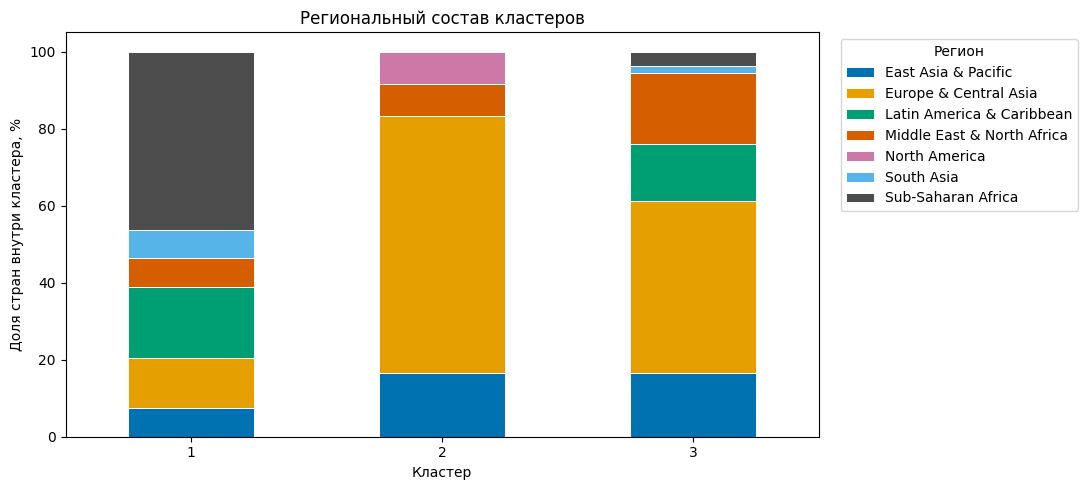

In [18]:
region_shares.plot(
    kind='bar', stacked=True, figsize=(11, 5),
    color=['#0072B2', '#E69F00', '#009E73', '#D55E00', '#CC79A7', '#56B4E9', '#4D4D4D'],
    edgecolor='white', linewidth=0.7
)
plt.title('Региональный состав кластеров')
plt.xlabel('Кластер')
plt.ylabel('Доля стран внутри кластера, %')
plt.xticks(rotation=0)
plt.legend(title='Регион', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

В первом кластере самая большая региональная группа это страны Африки к югу от Сахары - 25 из 54 или 46,3%. Ещё 10 стран относятся к Латинской Америке и Карибскому региону (18,5%). Это значит, что первый кластер не ограничивается одним регионом (к примеру той же Африкой), но, несмотря на это, почти половину его состава занимают страны Африки к югу от Сахары.

Во втором кластере преобладает Европа & Центральная Азия - 16 из 24 стран или 66,7%. Также сюда вошли 4 страны Восточной Азии & Тихоокеанского региона, 2 Ближнего Востока & Северной Африки и 2 страны Северной Америки.

В третьем кластере 24 страны относятся также к Европе & Центральной Азии (44,4%), 10 к Ближнему Востоку & Северной Африке (18,5%), девять к Восточной Азии & Тихоокеанскому региону (16,7%).

Страны одного региона попали в разные кластеры, поскольку группы формировались по инновационно-технологическим показателям. Поэтому каждый кластер объединяет страны из нескольких регионов.

**Доход и членство в ОЭСР**<br>

Сравним группы по категории Income. В файле используются три категории: high income, middle income и low income. Снова покажем количества и проценты внутри каждого кластера.

In [19]:
income_counts = pd.crosstab(df1['cluster_labels'], df1['Income'])
display(income_counts)

income_shares = pd.crosstab(
    df1['cluster_labels'], df1['Income'], normalize='index'
) * 100
display(income_shares.round(1))

Income,high income,low income,middle income
cluster_labels,,,
1,1,13,40
2,23,0,1
3,27,0,27


Income,high income,low income,middle income
cluster_labels,,,
1,1.9,24.1,74.1
2,95.8,0.0,4.2
3,50.0,0.0,50.0


В первом кластере 40 стран со средним доходом (74,1%), 13 с низким (24,1%) и одна с высоким (1,9%). Все 13 стран с низким доходом, вошедшие в выборку, находятся в первом кластере.

Во втором кластере 23 страны с высоким доходом (95,8%) и одна со средним (4,2%).

В третьем кластере поровну стран с высоким и средним доходом - по 27 или по 50%. Значит, высокий инновационно-технологический уровень группы связан с высоким доходом, но эти признаки не совпадают полностью, так как страны с высоким доходом есть во всех трёх кластерах.

In [20]:
oecd_counts = pd.crosstab(df1['cluster_labels'], df1['OECD members'])
display(oecd_counts)

oecd_shares = pd.crosstab(
    df1['cluster_labels'], df1['OECD members'], normalize='index'
) * 100
display(oecd_shares.round(1))

oecd_distribution = pd.crosstab(
    df1['cluster_labels'], df1['OECD members'], normalize='columns'
) * 100
display(oecd_distribution.round(1))

OECD members,0,1
cluster_labels,,
1,54,0
2,3,21
3,37,17


OECD members,0,1
cluster_labels,,
1,100.0,0.0
2,12.5,87.5
3,68.5,31.5


OECD members,0,1
cluster_labels,,
1,57.4,0.0
2,3.2,55.3
3,39.4,44.7


В столбце OECD members значение 1 обозначает членство в ОЭСР, 0 его отсутствие.

В первом кластере членов ОЭСР нет. Во втором их 21 из 24 стран или 87,5%. В третьем их 17 из 54 или 31,5%.

Последняя таблица отвечает на другой вопрос - куда распределились, в какие кластеры, страны-члены ОЭСР? 
Из всех 38 членов ОЭСР в рабочей выборке 21 страна (55,3%) попала во второй кластер и 17 (44,7%) в третий. Таким образом, более половины членов ОЭСР находится во втором кластере, но ,опять же, членство не означает обязательного попадания именно в эту группу.

**Проанализируем, почему получилась такая структура и что оказалось интересным**<br>

Посмотрим на несколько конкретных стран. <br>
Австралия и Новая Зеландия имеют высокий доход и входят в ОЭСР по данным файла, но находятся в третьем кластере. <br>
Малайзия имеет средний доход и не входит в ОЭСР, но попала во второй.<br> 
Сопоставим их категории с некоторыми исходными признаками.

In [21]:
example_countries = ['Australia', 'New Zealand', 'Malaysia']
example_features = [
    'Graduates in science and engineering, %_2022',
    'Gross expenditure on R&D, % GDP_2022',
    'High-tech manufacturing, %_2022',
    'High-tech exports, % total trade_2022'
]

country_examples = df1.loc[
    df1['Country'].isin(example_countries),
    ['Country', 'cluster_labels', 'Income', 'OECD members'] + example_features
]
display(country_examples.rename(columns=feature_names).round(2))

,Country,cluster_labels,Income,OECD members,Выпускники науки и инженерии,Расходы на НИОКР,Высокотехнологичное производство,Высокотехнологичный экспорт
95,Australia,3,high income,1,30.9,33.5,31.8,28.5
105,Malaysia,2,middle income,0,99.6,19.0,60.3,100.0
108,New Zealand,3,high income,1,45.7,25.9,21.0,32.0


**Почему группы различаются?**<br>
Кластеризация проводилась по двум компонентам, построенным из показателей госуправления, инфраструктуры, образования, науки и технологичного сектора. Многие исходные признаки положительно связаны друг с другом, поэтому первая компонента объединила общий уровень этих признаков. Она имеет больший разброс и сильнее влияет на евклидовы расстояния. Метод Варда объединял страны с близкими значениями компонент, поэтому основное разделение получилось по общему инновационно-технологическому уровню.

**Что выглядит ожидаемым**<br>
Во втором кластере почти все страны имеют высокий доход, и большинство входит в ОЭСР. Это согласуется с высокими средними по НИОКР, инфраструктуре и технологичному сектору из пункта 2. Первый кластер, наоборот, включает все страны с низким доходом из рабочей выборки и не включает членов ОЭСР. Такая связь выглядит объяснимой, но проведённые расчёты не доказывают, что конкретно доход или членство в ОЭСР являются причиной попадания в конкретный кластер.

**Что не совпадает с простым ожиданием?**<br>
Можно было бы предположить, что все страны с высоким доходом и все члены ОЭСР попадут во второй кластер. Однако Австралия и Новая Зеландия оказались в третьем, хотя соответствуют обоим условиям. 
Чтобы понять этот результат, посмотрим на их исходные признаки. Значения высокотехнологичного производства у них равны 31,8 и 21,0, а экспорта 28,5 и 32,0. Оба показателя ниже средних второго кластера, которые составляют 61,51 и 61,57 соответственно. Это помогает объяснить положение Австралии и Новой Зеландии в третьей группе. При этом распределение определяется совокупностью всех десяти показателей через PCA, а не только производством и экспортом.

У Малайзии, напротив, высоки значения показателей технических выпускников (99,6), высокотехнологичного производства (60,3) и экспорта (100,0). Это помогает объяснить её попадание во второй кластер несмотря на категорию среднего дохода.

**Итог по пункту 3.**<br>
Состав кластеров различается по регионам, доходу и членству в ОЭСР. В первом кластере преобладают страны со средним и низким доходом, во втором, наоборот,  с высоким, а третий объединяет страны с высоким и средним доходом в равных долях. Члены ОЭСР распределились между вторым и третьим кластерами.

Таким образом, разбиение связано с экономическими и региональными характеристиками, которые не участвовали в построении модели, но не повторяет их полностью.

**Дополнительное сравнение трёх моделей**<br>

Сравним метод Варда, k-means и DBSCAN на той же таблице X_cluster. Число компонент и их масштаб сохраняем. Это позволит сравнить именно алгоритмы при одинаковом признаковом пространстве.

Для Варда оставим выбранные в основной части три кластера. Для k-means проверим варианты от 2 до 10 и отдельно сопоставим трёхкластерное решение с Вардом. Также для DBSCAN переберём параметры.

In [22]:
kmeans_results = []

for comparison_k in range(2, 11):
    kmeans_labels = KMeans(
        n_clusters=comparison_k, random_state=228, n_init=20
    ).fit_predict(X_cluster)
    kmeans_results.append({
        'Число кластеров': comparison_k,
        'Калински-Харабаш': calinski_harabasz_score(X_cluster, kmeans_labels),
        'Силуэт': silhouette_score(X_cluster, kmeans_labels)
    })

kmeans_results = pd.DataFrame(kmeans_results)
display(kmeans_results.round(3))

,Число кластеров,Калински-Харабаш,Силуэт
0,2,184.318,0.479
1,3,186.747,0.440
2,4,165.929,0.398
3,5,149.236,0.372
4,6,146.489,0.348
5,7,144.743,0.332
6,8,142.487,0.337
7,9,140.358,0.343
8,10,144.761,0.354


**График локтя для k-means**<br>
Как было на семинаре, посмотрим на инерцию при разном количестве кластеров.Проверим от 1 до 10 групп.

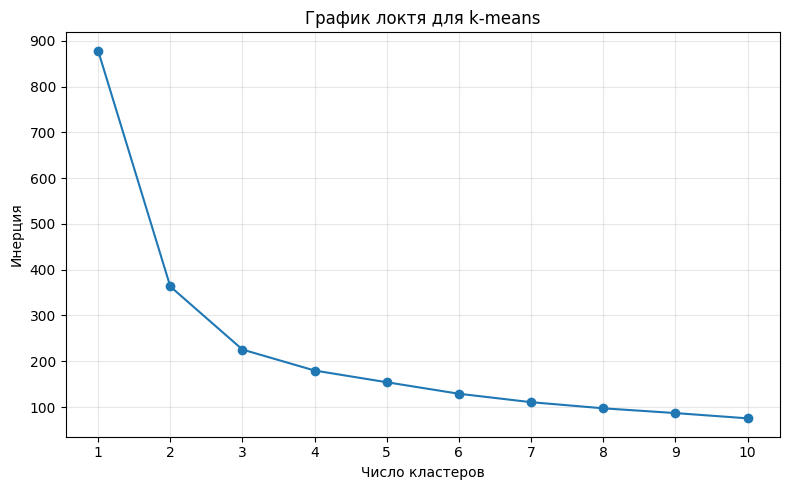

In [23]:
elbow_inertia = []
elbow_k_range = range(1, 11)

for elbow_k in elbow_k_range:
    elbow_model = KMeans(n_clusters=elbow_k, random_state=228, n_init=20)
    elbow_model.fit(X_cluster)
    elbow_inertia.append(elbow_model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(elbow_k_range, elbow_inertia, marker='o')
plt.title('График локтя для k-means')
plt.xlabel('Число кластеров')
plt.ylabel('Инерция')
plt.xticks(elbow_k_range)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Наибольшее снижение инерции происходит при переходе от одной группы к двум. При добавлении третьей группы она ещё заметно снижается, а дальше изменения становятся меньше. График позволяет рассматривать два или три кластера, но однозначного выбора только по нему сделать не можем. С учётом максимального индекса Калински-Харабаша и задачи получить более подробное разбиение оставим три группы.

Для k-means наибольший индекс Калински-Харабаша получен при трёх кластерах (186,75), а наибольший силуэт при двух (0,479). Как и для Варда, метрики предлагают разные решения. Для дальнейшего сравнения выберем три группы, этот вариант имеет максимальный индекс Калински-Харабаша среди проверенных значений и позволяет сопоставить такое же количество групп с основным решением.

В k-means задан random_state=228, чтобы результат можно было воспроизвести.

**Подбор параметров DBSCAN**<br>
Проверим eps от 0,3 до 1,5 с шагом 0,1 и min_samples из значений 3, 5 и 8. Радиус измеряется в том же пространстве PC1–PC2. Метка −1 обозначает шум, т.е. страны, которые DBSCAN не присоединил к кластеру.

Силуэт и индекс Калински-Харабаша для DBSCAN считаем только по странам без метки −1 и только если получилось не менее двух кластеров. Для выбора параметров рассматриваем варианты, распределяющие по кластерам не менее 80% стран (просто порог, который я задал конкретно для этой задачи). Среди таких вариантов выберем наибольший силуэт, а при равном силуэте предпочтём больший охват стран.

In [24]:
dbscan_results = []

for comparison_eps in np.round(np.arange(0.3, 1.6, 0.1), 1):
    for comparison_min_samples in [3, 5, 8]:
        
        dbscan_labels = DBSCAN(
            eps=comparison_eps, min_samples=comparison_min_samples
        ).fit_predict(X_cluster)
        
        assigned = dbscan_labels != -1
        group_count = len(set(dbscan_labels[assigned]))
        dbscan_silhouette = np.nan
        dbscan_ch = np.nan

        if 2 <= group_count and group_count < assigned.sum():
            dbscan_silhouette = silhouette_score(
                X_cluster.loc[assigned], dbscan_labels[assigned]
            )
            dbscan_ch = calinski_harabasz_score(
                X_cluster.loc[assigned], dbscan_labels[assigned]
            )

        dbscan_results.append({
            'eps': comparison_eps,
            'min_samples': comparison_min_samples,
            'Кластеров': group_count,
            'Шум': (~assigned).sum(),
            'Охват, %': assigned.mean() * 100,
            'Силуэт': dbscan_silhouette,
            'Калински-Харабаш': dbscan_ch
        })

dbscan_results = pd.DataFrame(dbscan_results)
dbscan_candidates = dbscan_results.loc[
    (dbscan_results['Охват, %'] >= 80) & dbscan_results['Силуэт'].notna()
].sort_values(['Силуэт', 'Охват, %'], ascending=False)

display(dbscan_candidates.round(3))
best_dbscan = dbscan_candidates.iloc[0]

,eps,min_samples,Кластеров,Шум,"Охват, %",Силуэт,Калински-Харабаш
13,0.7,5,2,22,83.333,0.491,74.951
20,0.9,8,2,16,87.879,0.467,73.849
16,0.8,5,2,16,87.879,0.451,67.663
9,0.6,3,3,19,85.606,0.289,17.212


**Тепловые карты подбора DBSCAN**<br>
Как в семинаре, покажем результаты перебора на тепловых картах: по горизонтали eps, по вертикали min_samples. Первая карта показывает количество кластеров без учёта шума. Вторая - силуэт без шума только для вариантов с охватом не менее 80% стран. Пустые ячейки второй карты означают, что вариант не прошёл ограничение по охвату или для него нельзя рассчитать силуэт из-за количества групп.

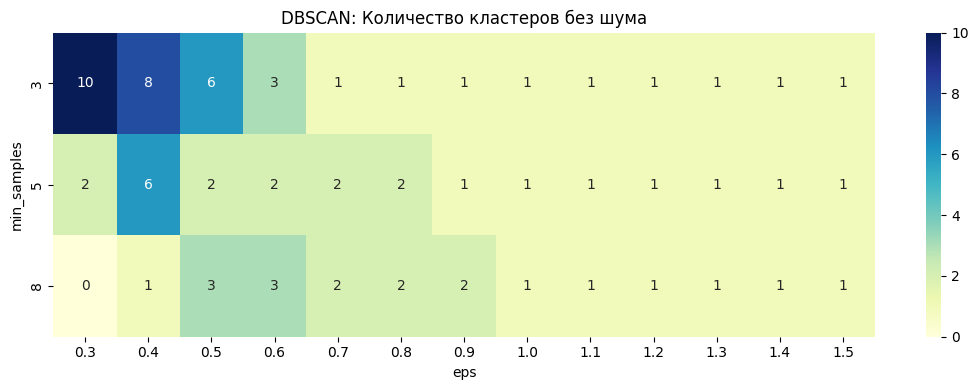

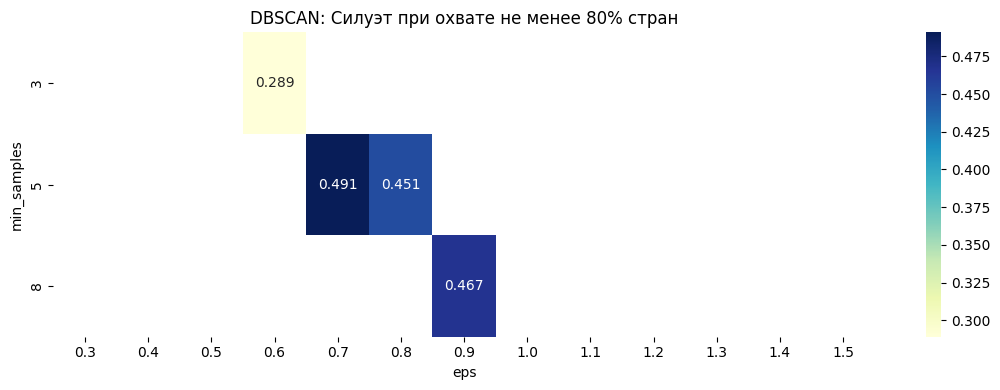

In [25]:
dbscan_cluster_map = dbscan_results.pivot(
    index='min_samples', columns='eps', values='Кластеров'
)

plt.figure(figsize=(11, 4))
sns.heatmap(dbscan_cluster_map, annot=True, fmt='d', cmap='YlGnBu')
plt.title('DBSCAN: Количество кластеров без шума')
plt.xlabel('eps')
plt.ylabel('min_samples')
plt.tight_layout()
plt.show()

dbscan_silhouette_map = dbscan_results.pivot(
    index='min_samples', columns='eps', values='Силуэт'
)
dbscan_coverage_map = dbscan_results.pivot(
    index='min_samples', columns='eps', values='Охват, %'
)

plt.figure(figsize=(11, 4))
sns.heatmap(
    dbscan_silhouette_map, mask=dbscan_coverage_map < 80,
    annot=True, fmt='.3f', cmap='YlGnBu'
)
plt.title('DBSCAN: Силуэт при охвате не менее 80% стран')
plt.xlabel('eps')
plt.ylabel('min_samples')
plt.tight_layout()
plt.show()

Среди проверенных вариантов, прошедших ограничение по охвату и числу групп, выбран DBSCAN с eps=0,7 и min_samples=5. Он выделил два кластера. Ещё 22 страны (16,7% выборки) отнесены к шуму. Силуэт на 110 распределённых странах равен 0,491.

Высокий силуэт здесь получен после исключения части стран. Поэтому сначала покажем метрики и охват каждого алгоритма, а затем отдельно сравним все три модели на одних и тех же 110 странах, которые DBSCAN не отнёс к шуму. Это позволит отделить различия алгоритмов от различий в составе оцениваемой выборки.

In [26]:
comparison_labels = pd.DataFrame(index=X_cluster.index)

comparison_labels['Ward'] = fcluster(Z, t=3, criterion='maxclust')
comparison_labels['k-means'] = KMeans(
    n_clusters=3, random_state=228, n_init=20
).fit_predict(X_cluster)
comparison_labels['DBSCAN'] = DBSCAN(
    eps=best_dbscan['eps'], min_samples=int(best_dbscan['min_samples'])
).fit_predict(X_cluster)

comparison_rows = []
common_rows = []
common_mask = (comparison_labels != -1).all(axis=1)

for model_name in comparison_labels:
    model_labels = comparison_labels[model_name]
    assigned = model_labels != -1
    comparison_rows.append({
        'Модель': model_name,
        'Кластеров': model_labels[assigned].nunique(),
        'Стран в кластерах': assigned.sum(),
        'Шум': (~assigned).sum(),
        'Силуэт': silhouette_score(X_cluster.loc[assigned], model_labels[assigned]),
        'Калински-Харабаш': calinski_harabasz_score(X_cluster.loc[assigned], model_labels[assigned])
    })

    common_silhouette = np.nan
    common_ch = np.nan
    if 2 <= model_labels[common_mask].nunique() and model_labels[common_mask].nunique() < common_mask.sum():
        common_silhouette = silhouette_score(X_cluster.loc[common_mask], model_labels[common_mask])
        common_ch = calinski_harabasz_score(X_cluster.loc[common_mask], model_labels[common_mask])
    common_rows.append({
        'Модель': model_name,
        'Стран': common_mask.sum(),
        'Силуэт': common_silhouette,
        'Калински-Харабаш': common_ch
    })

model_comparison = pd.DataFrame(comparison_rows).set_index('Модель')
common_comparison = pd.DataFrame(common_rows).set_index('Модель')
print('Метрики на странах, распределённых каждым алгоритмом:')
display(model_comparison.round(3))
print('Метрики на общей выборке без шума DBSCAN:')
display(common_comparison.round(3))

Метрики на странах, распределённых каждым алгоритмом:


,Кластеров,Стран в кластерах,Шум,Силуэт,Калински-Харабаш
Модель,,,,,
Ward,3,132,0,0.433,177.629
k-means,3,132,0,0.440,186.747
DBSCAN,2,110,22,0.491,74.951


Метрики на общей выборке без шума DBSCAN:


,Стран,Силуэт,Калински-Харабаш
Модель,,,
Ward,110,0.487,181.943
k-means,110,0.491,191.070
DBSCAN,110,0.491,74.951


**Сравнение качества**<br>
На всех 132 странах k-means с тремя кластерами немного превосходит Варда по обеим метрикам - силуэт 0,440 против 0,433, индекс Калински-Харабаша 186,75 против 177,63.

На общей выборке из 110 стран силуэт k-means = 0,491, Варда = 0,487, DBSCAN = 0,491. Силуэты k-means и DBSCAN выглядят одинаковыми, но индекс Калински-Харабаша у k-means значительно выше: 191,07 против 74,95 у DBSCAN. У Варда индекс = 181,94.

Ниже покажем размеры групп и графики. Шум DBSCAN обозначим серыми крестиками.

Ward


,Количество стран
Ward,
1,54
2,24
3,54


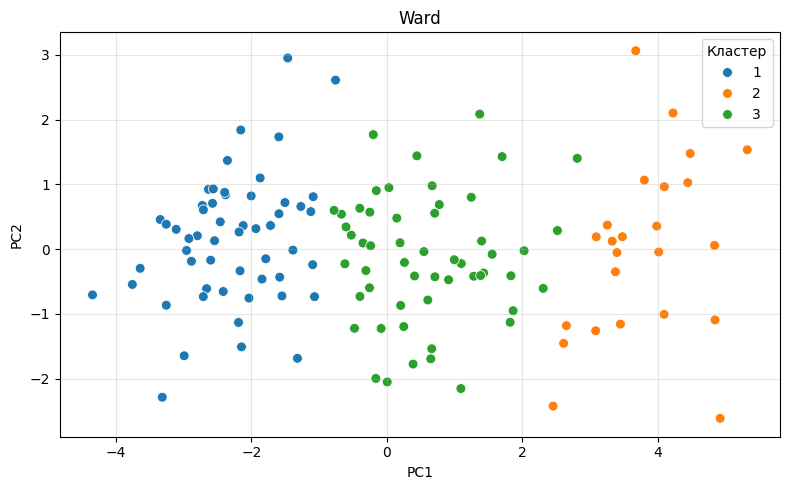

k-means


,Количество стран
k-means,
0,27
1,54
2,51


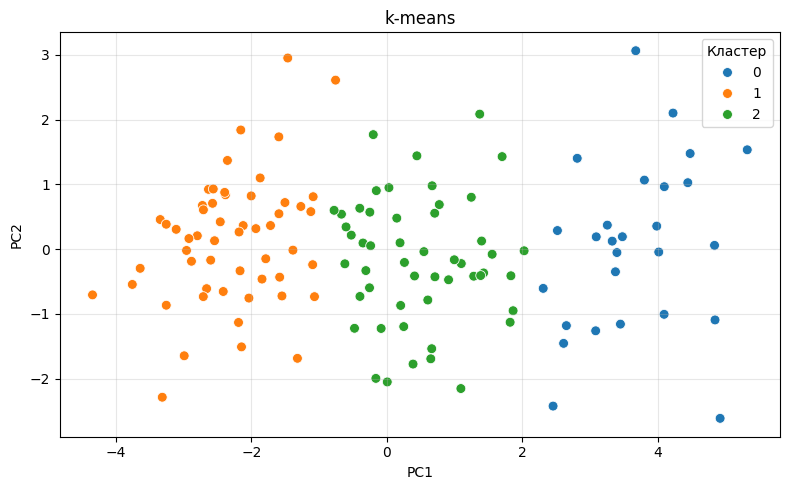

DBSCAN


,Количество стран
DBSCAN,
-1,22
0,98
1,12


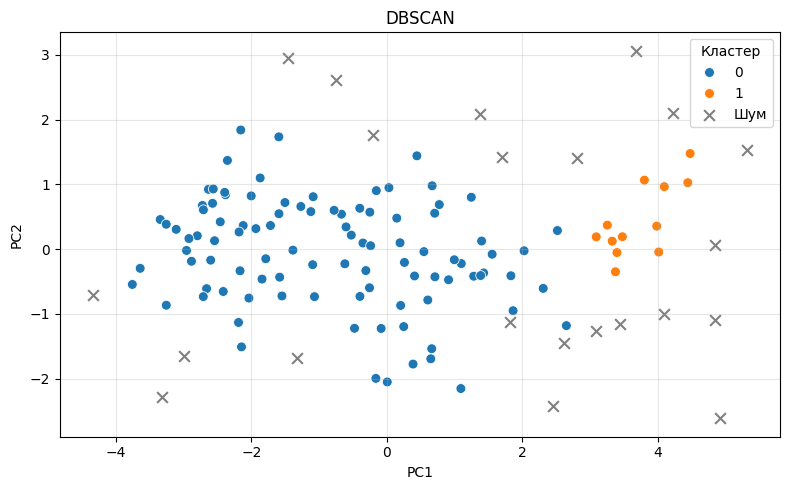

In [27]:
for model_name in comparison_labels:
    model_labels = comparison_labels[model_name]
    print(model_name)
    display(model_labels.value_counts().sort_index().to_frame('Количество стран'))

    assigned = model_labels != -1
    plt.figure(figsize=(8, 5))
    sns.scatterplot(
        data=X_cluster.loc[assigned], x='PC1', y='PC2',
        hue=model_labels[assigned], palette='tab10', s=50
    )
    if (~assigned).any():
        plt.scatter(
            X_cluster.loc[~assigned, 'PC1'], X_cluster.loc[~assigned, 'PC2'],
            color='gray', marker='x', s=60, label='Шум'
        )
    plt.title(model_name)
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.legend(title='Кластер')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

**Насколько похожи Вард и k-means?**<br>
Сопоставим принадлежность стран к группам двух моделей. Также посчитаем скорректированный индекс Рэнда (ARI). Он сравнивает разбиения независимо от номеров кластеров: 1 означает полное совпадение, значение около 0 говорит о том, что сходство на уровне случайного разбиения. Это не доля правильно классифицированных стран.

In [28]:
ward_kmeans_table = pd.crosstab(
    comparison_labels['Ward'], comparison_labels['k-means']
)
display(ward_kmeans_table)

ward_kmeans_ari = adjusted_rand_score(
    comparison_labels['Ward'], comparison_labels['k-means']
)
print('ARI Варда и k-means:', round(ward_kmeans_ari, 3))

k-means,0,1,2
Ward,,,
1,0,54,0
2,24,0,0
3,3,0,51


ARI Варда и k-means: 0.943


ARI равен 0,943, то есть разбиения очень близки. Из таблицы видно, что первая группа Варда полностью совпадает с группой 1 у k-means. Все 24 страны второй группы Варда входят в группу 0 у k-means, вместе с ещё тремя странами из третьей группы Варда. Остальные 51 страна третьей группы образуют группу 2 у k-means. В итоге принадлежность совпадает у 129 из 132 стран.

**Вывод по дополнительному сравнению**<br>
При выбранных двух компонентах и трёх группах k-means немного предпочтительнее Варда по обеим рассчитанным метрикам. Его результат можно выбрать как лучший из этих двух трёхкластерных вариантов по численным показателям. При этом Вард даёт очень близкое разбиение и позволяет объяснить структуру объединений на дендрограмме.

DBSCAN при выбранных параметрах не даёт преимущества для разбиения всех стран, он оставляет 22 наблюдения без кластера и формирует сильно различающиеся по размеру группы. Его было бы удобнее использовать, если бы отдельной целью был поиск малоплотных наблюдений.

### Комментарии к заданию и принципам его оценивания:
 
 - Все пункты задания должны сопровождаться _выполненным_ фрагментом кода.
 - Если результаты в виде статистических показателей, таблиц или графиков никак не прокомментированы и отсутствуют содержательные выводы на их основе, то работа оценивается в 0 баллов, в этом случае анализ данных не проведён.
 - Правильно выполненное задание оценивается в 8 баллов (отлично). Для получения более высокой оценки нужно выйти за рамки предложенного задания. В случае с текущим заданием это может быть дополнительное самостоятельное изучение других алгоритмов кластеризации и их применение для анализа данных, или развернутое и глубокое исследование имеющихся данных на основе применения всех пройденных на занятиях алгоритмов кластеризации, сравнением результатов и выбором лучшей кластерной модели с объяснением своего выбора.
 - В задании три пункта. Вес первого - 35%, второго - 50%, третьего - 15%. 
 - Задание можно выполнять индивидуально или в группе из 2 человек, критерии оценивания при этом остаются одинаковыми.
 - Если задание выполняется вдвоем, то в Smart LMS ноутбук с решениями загружает только один из студентов.
 - В названии загружаемого в Smart LMS файла нужно указать фамилию(ии) автора(ов) работы.
 - При использовании инструментов искусственного интеллекта необходимо отметить это в работе в соответствии с правилами НИУ ВШЭ.

### Этот файл нужно сохранить как Jupyter Notebook (.ipynb) и загрузить в Smart LMS до 21:00 9 ноября. Не рекомендую загружать файл в Smart LMS в последние несколько минут перед дедлайном. После дедлайна выполненные задания не принимаются.